# Extracting features from gestures and sign

In [2]:
import os
import glob
import pandas as pd
import numpy as np
from scipy.signal import find_peaks
import antropy as ent

curfolder = os.getcwd()
datasetsfolder = os.path.join(curfolder, 'Datasets')
processedfolder = os.path.join(curfolder, 'TS_processed')

# Gross motorics (arm)

In [ ]:

mtfiles = glob.glob(os.path.join(processedfolder, '*body_world.csv'))
#handfiles = glob.glob(os.path.join(processedfolder, '*hands_world.csv'))

# how many files do we have?
print('Number of files:', len(mtfiles))

Number of files: 12867


## Delete problematic files

In [2]:
# load in problems_visibility_all.txt
problems_visibility = pd.read_csv(os.path.join(curfolder, 'problems_visibility_all.txt'), sep='\t', header=None)

# create col ID and take first element of the string _
# if flipped in 0, take first two, otherwise take first one
if problems_visibility[0].str.contains('flipped_').any():
    problems_visibility['ID'] = problems_visibility[0].apply(lambda x: x.split('_')[0] + '_' + x.split('_')[1])
else:
    problems_visibility['ID'] = problems_visibility[0].apply(lambda x: x.split('_')[0])

# how many unique IDs do we have?
print('Number of unique IDs in problems_visibility:', len(problems_visibility['ID'].unique()))

# how many times is each ID in problems_visibility?
print('Number of times each ID appears in problems_visibility:')
print(problems_visibility['ID'].value_counts())

# add .csv to the first column
problems_visibility[0] = problems_visibility[0].apply(lambda x: x + '.csv')

Number of unique IDs in problems_visibility: 40
Number of times each ID appears in problems_visibility:
ID
LP01     215
LP38     196
LP18     166
LP17     122
IP08     118
LP07     107
LP14     104
LP42      95
LP43      92
LP40      81
LP22      79
IP14      74
LP06      71
LP41      67
IP10      65
LP08      60
IP16      52
LP34      52
LP25      42
GP16      10
LP29      10
GP11       8
GP14       5
GP05       5
LP13       4
GP08       4
GP02       3
ViCom      3
GP17       3
GP04       2
LP36       2
GP10       2
IP11       2
IP04       1
IP06       1
LP04       1
GP01       1
LP30       1
GP03       1
IP18       1
Name: count, dtype: int64


For now, we will get rid of them to ensure the best quality MT

In [4]:
# get rid of files from mtfiles that match first column of problems_visibility
mtfiles_clean = [f for f in mtfiles if os.path.basename(f) not in problems_visibility[0].values]

# how many is in mtfiles_clean?
print('Number of files in mtfiles_clean:', len(mtfiles_clean))

# how much % was removed from mtfiles?
print('Percentage of files removed from mtfiles:', (len(mtfiles) - len(mtfiles_clean)) / len(mtfiles) * 100)


Number of files in mtfiles_clean: 10939
Percentage of files removed from mtfiles: 14.98406777026502


## Functions needed

### BBMV 

In [5]:
## function to calculate bbmv
def get_bbmv(df, keypoint):
    # get spans in each dimension
    x_span = df['X_' + keypoint].max() - df['X_' + keypoint].min()
    y_span = df['Y_' + keypoint].max() - df['Y_' + keypoint].min()
    z_span = df['Z_' + keypoint].max() - df['Z_' + keypoint].min()

    # calculate bbmv
    bbmv = x_span * y_span * z_span

    return bbmv

### Intermittency

In [6]:
## function for intermittency (adapted from Wim's paper)
def get_intermittency(jerk_values, speed_values):
    """Calculate the dimensionless smoothness measure using precomputed smoothed jerk and speed."""
    smoothed_jerk = jerk_values
    speed = speed_values
    
    if not np.all(speed == 0):
        integrated_squared_jerk = np.sum(smoothed_jerk ** 2)
        max_squared_speed = np.max(speed ** 2)
        D3 = len(speed) ** 3
        jerk_dimensionless = integrated_squared_jerk * (D3 / max_squared_speed)
        smoothness = jerk_dimensionless
    else:
        smoothness = np.nan

    return smoothness


### Arm coupling and (a)symmetry

In [7]:

def compute_ArmCoupling(df, keypoints=['WRIST'], dimensions=['X', 'Y', 'Z'], absolute=True):
    correlations = []
    
    for kp in keypoints:
        for dim in dimensions:
            left_col = f"{dim}_LEFT_{kp}"
            right_col = f"{dim}_RIGHT_{kp}"
                
            if left_col in df.columns and right_col in df.columns:
                corr = np.corrcoef(df[left_col], df[right_col])[0, 1]  # Pearson correlation
                if absolute:
                    corr = np.abs(corr)
                correlations.append(corr)
    
    return np.nanmean(correlations)  # Average correlation across keypoints and dimensions

def compute_multimovementAssymetry(df):
    joints = ['ELBOX', 'WRIST', 'SHOULDER']
    
    integral_diff_left = 0
    integral_diff_right = 0
    joint_integral_differences = []

    for joint in joints:
        joint_r_speed = f"RIGHT_{joint}_speed"
        joint_l_speed = f"LEFT_{joint}_speed"
            
        if joint_r_speed in df.columns and joint_l_speed in df.columns:
            # Compute the integral of velocity (sum of speed over time) for left and right joints
            integral_velocity_left = np.sum(np.abs(df[joint_l_speed]))  # Sum of absolute speed
            integral_velocity_right = np.sum(np.abs(df[joint_r_speed]))  # Sum of absolute speed

            # Compute the difference in integral of angular velocity between left and right 
            # the more +, the more distance is left is travelling), 
            joint_integral_diff = integral_velocity_left - integral_velocity_right
            joint_integral_differences.append(joint_integral_diff)

            # Accumulate for total integral difference calculation
            integral_diff_left += integral_velocity_left
            integral_diff_right += integral_velocity_right

    # Compute the overall difference in integrated velocities
    total_integral_difference = np.mean(joint_integral_differences)  # Mean of differences across joints

    return {
        'mean_integral_difference': total_integral_difference,
        'joint_integral_differences': joint_integral_differences,
        'total_left_integral_velocity': integral_diff_left,
        'total_right_integral_velocity': integral_diff_right
    }


### Peaks

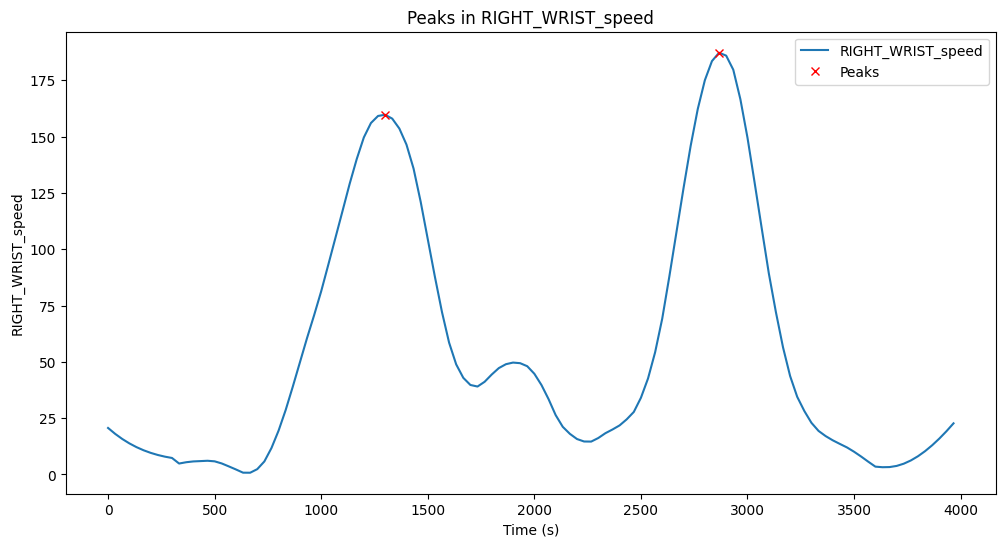

In [9]:
from scipy.signal import find_peaks
from scipy.stats import median_abs_deviation
import matplotlib.pyplot as plt

def compute_peaks(df, col, fs, plot=False):

    scale = median_abs_deviation(df[col], scale='normal')
    if 'speed' in col:
        distance = int(0.2 * fs)
        prominence = scale * 0.6
        signal_for_peaks = df[col].values   

    elif 'acceleration' in col:
        distance = int(0.1 * fs)
        prominence = scale * 0.6
        signal_for_peaks = np.abs(df[col].values)  # Use absolute values for acceleration peaks

    else:
        distance = int(0.2 * fs)
        prominence = scale * 0.6
        signal_for_peaks = df[col].values
    
    peak, _ = find_peaks(signal_for_peaks, distance=distance, prominence=prominence)
    # find the peak values
    peak_values = df.loc[peak, col]
    # find the peak times
    peak_times = df.loc[peak, 'time'].tolist()
    # get peak mean
    peak_mean = peak_values.mean()
    # get peak std
    peak_std = peak_values.std()
    # peak n
    peak_n = len(peak_values)

    if plot:
        plt.figure(figsize=(12, 6))
        plt.plot(df['time'], signal_for_peaks, label=col)
        plt.plot(df.loc[peak, 'time'], signal_for_peaks[peak], 'rx', label='Peaks')
        plt.title(f'Peaks in {col}')
        plt.xlabel('Time (s)')
        plt.ylabel(col)
        plt.legend()
        plt.show()

    return peak_mean, peak_std, peak_n, peak_times

df = pd.read_csv(mtfiles_clean[50])
fs = 30.0  # sampling frequency
peak_mean, peak_std, peak_n, peak_times = compute_peaks(df, 'RIGHT_WRIST_speed', fs, plot=True)


### Spectral properties (rhytmicity)

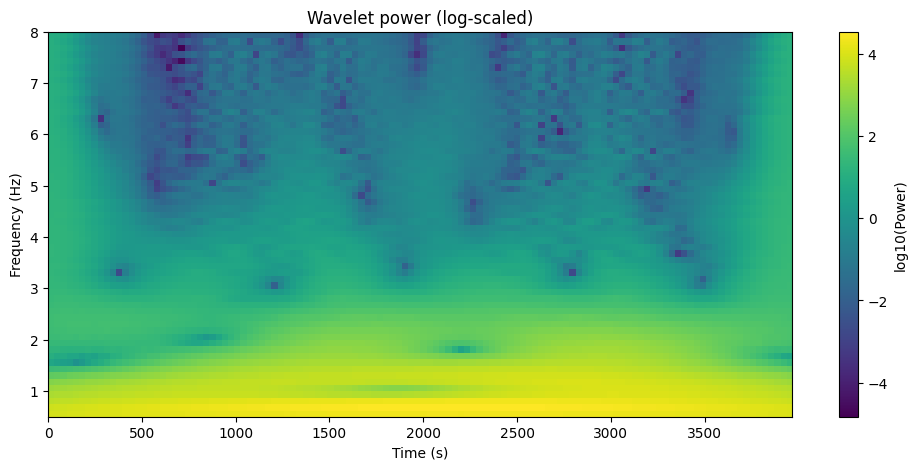

In [10]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

def wavelet_rhythmicity_features_3bands(
    speed,
    time,
    bands=((0.5, 2.0), (2.0, 5.0), (5.0, 8.0)),
    n_freqs=60,
    plot=False
):
    """
    Wavelet-based rhythmicity features for multiple frequency bands.

    bands: list of (fmin, fmax) tuples
           e.g. [(0.5,2), (2,5), (5,8)]

    Returns: dict of features with band-specific prefixes
    """

    speed = np.asarray(speed)
    time = np.asarray(time)

    duration = time[-1] - time[0]
    dt = np.median(np.diff(time))
    fs = 30

    features = {}

    if duration < 0.7:
        # Too short for meaningful rhythmicity
        for i, (fmin, fmax) in enumerate(bands):
            prefix = f"band{i+1}_{fmin}-{fmax}Hz"
            features[prefix + "_dom_freq"] = np.nan
            features[prefix + "_centroid"] = np.nan
            features[prefix + "_band_power"] = np.nan
            features[prefix + "_entropy"] = np.nan
            features[prefix + "_power_ratio"] = np.nan
        return features

    # Compute one wavelet transform covering all bands
    fmin_all = min(b[0] for b in bands)
    fmax_all = max(b[1] for b in bands)
    freqs = np.linspace(fmin_all, fmax_all, n_freqs)

    wavelet = 'cmor1.5-1.0'
    scales = pywt.central_frequency(wavelet) * fs / freqs

    coeffs, _ = pywt.cwt(speed, scales, wavelet, sampling_period=dt)
    power = np.abs(coeffs) ** 2

    if plot:
        # Log-scaled scalogram for diagnostics
        plt.figure(figsize=(12, 5))
        plt.imshow(
            np.log10(power + 1e-6),
            aspect='auto',
            extent=[time[0], time[-1], freqs[0], freqs[-1]],
            origin='lower'
        )
        plt.colorbar(label="log10(Power)")
        plt.xlabel("Time (s)")
        plt.ylabel("Frequency (Hz)")
        plt.title("Wavelet power (log-scaled)")
        plt.show()

    # Mean power spectrum over time
    mean_power = power.mean(axis=1)

    # Normalize spectrum to sum to 1 (for entropy, ratios)
    mean_power_norm = mean_power / (mean_power.sum() + 1e-12)

    for i, (fmin, fmax) in enumerate(bands):
        band_mask = (freqs >= fmin) & (freqs < fmax)
        band_freqs = freqs[band_mask]
        band_power = mean_power_norm[band_mask]

        prefix = f"band{i+1}_{fmin}-{fmax}Hz"

        if len(band_power) == 0 or np.all(band_power == 0):
            features[prefix + "_dom_freq"] = np.nan
            features[prefix + "_centroid"] = np.nan
            features[prefix + "_band_power"] = 0.0
            features[prefix + "_entropy"] = np.nan
            features[prefix + "_power_ratio"] = 0.0
            continue

        # Dominant frequency in this band
        dom_freq = band_freqs[np.argmax(band_power)]

        # Spectral centroid (center of mass of power in band)
        centroid = np.sum(band_freqs * band_power) / np.sum(band_power)

        # Band power (proportion of total spectral energy in this band)
        band_power_ratio = band_power.sum()   # already normalized

        # Spectral entropy within the band (regularity vs spread)
        p = band_power / (band_power.sum() + 1e-12)
        entropy = -np.sum(p * np.log(p + 1e-12))

        # Power ratio within band: peak power / total band power
        power_ratio = band_power.max() / (band_power.sum() + 1e-12)

        features[prefix + "_dom_freq"] = float(dom_freq)
        features[prefix + "_centroid"] = float(centroid)
        features[prefix + "_band_power"] = float(band_power_ratio)
        features[prefix + "_entropy"] = float(entropy)
        features[prefix + "_power_ratio"] = float(power_ratio)

    return features


df = pd.read_csv(mtfiles_clean[50])
features = wavelet_rhythmicity_features_3bands(df['RIGHT_WRIST_speed'], df['time'], plot=True)


## Extract features - full loop for body

In [12]:
from scipy.stats import median_abs_deviation
import warnings # surpress warnings
warnings.filterwarnings("ignore")

features_all_df = pd.DataFrame()

for file in mtfiles_clean:
    fname = os.path.basename(file)

    # get id
    if 'video_raw' in file:
        continue
    elif 'flipped' in file:
        continue
    else:
        id = file.split(os.sep)[-1].split('_')[0]

    print('working on file: ', fname)

    # Get sampling rate
    if fname.startswith("LP") or fname.startswith("GtST"):
        fs = 30
    else:
        fs = 50

    # load it in
    df = pd.read_csv(file)
    fileID = file.split(os.sep)[-1].split('.')[0]

    # if the file id contains LIGHTNING; TO-HEAR or GOAL,skip them because there are practice trials
    if 'LIGHTNING' in fileID or 'TO-HEAR' in fileID or 'GOAL' in fileID:
        continue

    # ARM KINEMATICS
    ## add basic statistics for total_arm_speed, total_arm_jerk, total_arm_acceleration
    #armtotalcols = ['total_arm_speed', 'total_arm_acceleration', 'RIGHT_WRIST_speed_norm', 'LEFT_WRIST_speed_norm', 'RIGHT_WRIST_acceleration_norm', 'LEFT_WRIST_acceleration_norm']
    armtotalcols = ['total_arm_speed', 'total_arm_acceleration']
    arms_summary = {}

    for col in armtotalcols:

        gmean = df[col].mean()         # general mean
        gstd = df[col].std()           # general std
        peak_mean, peak_std, peak_n, peak_times = compute_peaks(df, col, fs)
        #ts_range = df[col].max() - df[col].min()

        # save in a dictionary
        arms_summary[col] = [gmean, gstd, peak_mean, peak_std, peak_n]

    # make a row from the dictionary
    arms_summary_row = pd.DataFrame({key: [value] for key, value in arms_summary.items()})

    # for each column, create new column that will have the old name + _Gmean, _Gstd, _peak_mean, _peak_std, _peak_n
    for col in arms_summary_row.columns:
        arms_summary_row[col + '_Gmean'] = arms_summary_row[col].apply(lambda x: x[0])
        arms_summary_row[col + '_Gstd'] = arms_summary_row[col].apply(lambda x: x[1])
        arms_summary_row[col + '_peak_mean'] = arms_summary_row[col].apply(lambda x: x[2])
        arms_summary_row[col + '_peak_std'] = arms_summary_row[col].apply(lambda x: x[3])
        arms_summary_row[col + '_peak_n'] = arms_summary_row[col].apply(lambda x: x[4])
        #arms_summary_row[col + '_ts_range'] = arms_summary_row[col].apply(lambda x: x[5])

    # get rid of all cols that don't have Gmean, etc.
    arms_summary_row = arms_summary_row[[col for col in arms_summary_row.columns if 'Gmean' in col or 'Gstd' in col or 'peak_mean' in col or 'peak_std' in col or 'peak_n' in col or 'ipi_avg' in col or 'sampen' in col or 'integral' in col or 'ts_range' in col]]
    

    # EXTRA FEATURES 
    # calculate integral of speed for total distance
    integral_speed_arm_total = np.trapz(df['total_arm_speed'].values, dx=1/fs)
    #integral_speed_rwrist = np.trapz(df['RIGHT_WRIST_speed_norm'].values, dx=1/fs)
    # sample entropy of speed
    sampen_speed_arm_total = ent.sample_entropy(df['total_arm_speed'].values, order=2)
    #sampen_speed_rwrist = ent.sample_entropy(df['RIGHT_WRIST_speed_norm'].values, order=2)

    ### bbmv for WRIST, ELBOW, SHOULDER
    bbmv_lwrist = get_bbmv(df, 'LEFT_WRIST')
    bbmv_rwrist = get_bbmv(df, 'RIGHT_WRIST')   
    bbmv_lelbow = get_bbmv(df, 'LEFT_ELBOW')            ### BBMV SHOULD BE PROBABLY ALSO LOGGED
    bbmv_relbow = get_bbmv(df, 'RIGHT_ELBOW')
    bbmv_lshoulder = get_bbmv(df, 'LEFT_SHOULDER')
    bbmv_rshoulder = get_bbmv(df, 'RIGHT_SHOULDER')
    bbmv_arms = bbmv_lwrist + bbmv_rwrist + bbmv_lelbow + bbmv_relbow + bbmv_lshoulder + bbmv_rshoulder
  
    # intermittency for whole arm
    jerk_arm_total = df['total_arm_jerk']
    speed_arm_total = df['total_arm_speed']
    intermittency_arm_total = get_intermittency(jerk_arm_total, speed_arm_total)
    #intermittency_rwrist = get_intermittency(df['RIGHT_WRIST_jerk_norm'], df['RIGHT_WRIST_speed_norm'])

    # calculate arm coupling
    arm_coupling = compute_ArmCoupling(df, keypoints=['WRIST', 'ELBOW'], dimensions=['X', 'Y', 'Z'], absolute=True)
    # calculate multimovement assymetry
    multimovement_assymetry = compute_multimovementAssymetry(df)

    # create empty features_summary_row
    # features_summary_row = pd.DataFrame({
    #     'intermittency_arm_total': intermittency_arm_total,
    #     'intermittency_rwrist': intermittency_rwrist,
    #     'sampen_speed_arm_total': sampen_speed_arm_total,
    #     'sampen_speed_rwrist': sampen_speed_rwrist,
    #     'bbmv_arms': bbmv_arms,
    #     'arm_coupling': arm_coupling,
    #     'arm_asymmetry': multimovement_assymetry['mean_integral_difference']
    # }, index =[0])

    features_summary_row = pd.DataFrame({
        'intermittency_arm_total': intermittency_arm_total,
        'sampen_speed_arm_total': sampen_speed_arm_total,
        'bbmv_arms': bbmv_arms,
        'arm_coupling': arm_coupling,
        'arm_asymmetry': multimovement_assymetry['mean_integral_difference']
    }, index =[0])


    # power spectrum features for speed
    features_speed_arm_total = wavelet_rhythmicity_features_3bands(df['total_arm_speed'], df['time'], plot=False)
    #features_speed_rwrist = wavelet_rhythmicity_features_3bands(df['RIGHT_WRIST_speed_norm'], df['time'], plot=False)
    speed_power_row_total = pd.DataFrame(features_speed_arm_total, index=[0])
    # add to each column sufix _total_arm
    for col in speed_power_row_total.columns:
        speed_power_row_total[col + '_total_arm'] = speed_power_row_total[col]
        speed_power_row_total = speed_power_row_total.drop(columns=[col])
        # keep only 'band_power' and 'entropy'
    
    speed_power_row_total = speed_power_row_total[[col for col in speed_power_row_total.columns if 'band_power' in col or 'entropy' in col or 'centroid' in col or 'dom_freq' in col]]
    # speed_power_row_rwrist = pd.DataFrame(features_speed_rwrist, index=[0])
    # # add to each column sufix _rwrist
    # for col in speed_power_row_rwrist.columns:
    #     speed_power_row_rwrist[col + '_rwrist'] = speed_power_row_rwrist[col]
    #     speed_power_row_rwrist = speed_power_row_rwrist.drop(columns=[col])
 
    # HEAD
    # Amplitude and speed of nose (head)
    head_speed_mean = df['NOSE_speed'].mean()
    head_speed_sd = df['NOSE_speed'].std()
    # vertical amplitude of nose
    head_vertical_mean = df['Y_NOSE'].mean()
    head_vertical_sd = df['Y_NOSE'].std()
    # horizontal amplitude of nose
    head_horizontal_mean = df['X_NOSE'].mean()
    head_horizontal_sd = df['X_NOSE'].std()

    head_row = pd.DataFrame({
        'head_speed_mean': head_speed_mean,
        'head_speed_sd': head_speed_sd,
        'head_vertical_mean': head_vertical_mean,
        'head_vertical_sd': head_vertical_sd,
        'head_horizontal_mean': head_horizontal_mean,
        'head_horizontal_sd': head_horizontal_sd
    }, index=[0])


    ## DISTANCES
    distances = ['lwrist_centre', 'rwrist_centre']

    # get all the basic statistics for these distances
    distances_summary = {}
    for col in distances:
        gmean = df[col].mean()
        gstd = df[col].std()
        # find peaks, height as mean
        peak_mean, peak_std, peak_n, peak_times = compute_peaks(df, col, fs)
        #ts_range = df[col].max() - df[col].min()

        # save in a dictionary
        distances_summary[col] = [gmean, gstd, peak_mean, peak_std, peak_n]

    # make a row from the dictionary
    distances_summary_row = pd.DataFrame({key: [value] for key, value in distances_summary.items()})
    # for each column, create new column that will have the old name + _Gmean, _Gstd, _peak_mean, _peak_std, _peak_n
    for col in distances_summary_row.columns:
        distances_summary_row[col + '_Gmean'] = distances_summary_row[col].apply(lambda x: x[0])
        distances_summary_row[col + '_Gstd'] = distances_summary_row[col].apply(lambda x: x[1])
        distances_summary_row[col + '_peak_mean'] = distances_summary_row[col].apply(lambda x: x[2])
        distances_summary_row[col + '_peak_std'] = distances_summary_row[col].apply(lambda x: x[3])
        distances_summary_row[col + '_peak_n'] = distances_summary_row[col].apply(lambda x: x[4])
        #distances_summary_row[col + '_ts_range'] = distances_summary_row[col].apply(lambda x: x[5])

    # get rid of all cols that don't have Gmean, etc.
    distances_summary_row = distances_summary_row[[col for col in distances_summary_row.columns if 'Gmean' in col or 'Gstd' in col or 'peak_mean' in col or 'peak_std' in col or 'peak_n' in col or 'ipi_avg' in col or 'sampen' in col or 'integral' in col or 'ts_range' in col]]

    # get rid of 'accel_integral', 'plane_integral' or 'centre_integral
    distances_summary_row = distances_summary_row[[col for col in distances_summary_row.columns if 'accel_integral' not in col and 'plane_integral' not in col and 'centre_integral' not in col]]
    
    # META

    #  make an empty concept_row that we will fill with some values
    concept_row = pd.DataFrame({'fileID': None, 'concept': None, 'group': None}, index=[0])
    concept_row['fileID'] = fileID

    if 'GtST' in fileID or 'GP' in fileID:
        concept_row['group'] = fileID.split('_')[0]
    elif 'LP' in fileID or 'IP' in fileID:
        concept_row['group'] = fileID.split('_')[0] + '_' + fileID.split('_')[1]
    elif 'ViCom' in fileID:
        concept_row['group'] = 'GtST_w'
    else:
        print('ERROR: fileID not in GtST, GP, LP, IP')
        break

    # column concept
    if 'GtST' in fileID:
        concept_row['concept'] = fileID.split('_')[2]
    elif 'GP' in fileID:
        concept_row['concept'] = fileID.split('_')[1]
    elif 'LP' in fileID or 'IP' in fileID:
        concept_row['concept'] = fileID.split('_')[2]
    elif 'ViCom' in fileID:
        concept_row['concept'] = fileID.split('_')[3]

    # we need to correct few concepts
    if concept_row['concept'].values[0] == 'TO-PICK':
        concept_row['concept'] = 'TO-PLUCK'
    elif concept_row['concept'].values[0] == 'TO-MOVE-HOUSES':
        concept_row['concept'] = 'TO-MOVE'
    elif concept_row['concept'].values[0] == 'VIDEO-GAME':
        concept_row['concept'] = 'VIDEOGAME'

    # concat all rows to features_all_df
    features_all = pd.concat([concept_row, arms_summary_row, speed_power_row_total, distances_summary_row, head_row, features_summary_row], axis=1)
    features_all_df = pd.concat([features_all_df, features_all])

# save them all 
features_all_df.to_csv(os.path.join(datasetsfolder, 'features_gross_df_reduced.csv'), index=False)

working on file:  LP28_01_BASKETBALL_body_world.csv
working on file:  LP28_01_BEINE_body_world.csv
working on file:  LP28_01_BEOBACHTEN_body_world.csv
working on file:  LP28_01_BEZAHLEN_body_world.csv
working on file:  LP28_01_BIER_body_world.csv
working on file:  LP28_01_BILLIARD_body_world.csv
working on file:  LP28_01_BODEN_body_world.csv
working on file:  LP28_01_BRECHEN_body_world.csv
working on file:  LP28_01_BRIEF_body_world.csv
working on file:  LP28_01_BRILLE_body_world.csv
working on file:  LP28_01_BUCH_body_world.csv
working on file:  LP28_01_BUEGELN_body_world.csv
working on file:  LP28_01_DUSCHEN_body_world.csv
working on file:  LP28_01_EGAL_body_world.csv
working on file:  LP28_01_EI_body_world.csv
working on file:  LP28_01_EINLADEN_body_world.csv
working on file:  LP28_01_ESSEN_body_world.csv
working on file:  LP28_01_FEUER_body_world.csv
working on file:  LP28_01_FOTOGRAFIE_body_world.csv
working on file:  LP28_01_FRAGE_body_world.csv
working on file:  LP28_01_GEBURT_bo

In [13]:
# show me unique groups + counts
print('Unique groups in features_all_df:')
groups = features_all_df['group'].value_counts()
groups


Unique groups in features_all_df:


group
GP06         363
GP18         363
GP15         363
GP01         362
GP03         362
            ... 
IP08_02       19
LP01_01       17
LP38_01        4
ViCom_128      1
ViCom_164      1
Name: count, Length: 69, dtype: int64

## Aftermath

In [14]:
#dfs = [features_all_df, features_kin_df, features_dist_df, features_hand_df]
dfs = [features_all_df]


def classify_group(x):
    if 'IP' in x and '_02' in x:
        return 'Learners_2'
    elif 'IP' in x and '_01' in x:
        return 'Learners_1'
    elif 'LP' in x and '_02' in x:
        return 'Learners_2'
    elif 'LP' in x and '_01' in x:
        return 'Learners_1'
    elif 'GtST' in x or 'ViCom' in x:
        return 'DGS'
    elif 'GP' in x:
        return 'Gesture'
    elif 'test' in x:
        return 'test'
    else:
        return x

# for each df, replace the group names
for df in dfs:
    df['group'] = df['group'].apply(lambda x: 'ViCom' if 'ViCom_' in x else x)
    df['group'] = df['group'].apply(lambda x: 'ViCom' if 'GtST_' in x else x)
    df['groupID'] = df['group'].apply(classify_group)
    # filter out rows where group=test or groupID=test
    df = df[df['group'] != 'test']
    df = df[df['groupID'] != 'test']

# save them datasetsfolder
features_all_df.to_csv(os.path.join(datasetsfolder, 'features_gross_df_final_reduced.csv'), index=False)


In [15]:
# within each col groupID, how many different values of col group there is?
group_counts = features_all_df.groupby('groupID')['group'].nunique().reset_index()
group_counts.columns = ['groupID', 'unique_groups_count']
group_counts


,groupID,unique_groups_count
0,DGS,2
1,Gesture,14
2,Learners_1,31
3,Learners_2,20


In [16]:
# unique values of groupID
print('Unique values of groupID in df:')
print(features_all_df['groupID'].unique())


Unique values of groupID in df:
['Learners_1' 'Learners_2' 'DGS' 'Gesture']


In [19]:
# show me percentage of nans per column
nan_percentage = features_all_df.isna().mean() * 100
print('Percentage of NaNs per column:')
nan_percentage[nan_percentage > 0].sort_values(ascending=False)



Percentage of NaNs per column:


rwrist_centre_peak_std             21.015946
lwrist_centre_peak_std             20.347560
lwrist_centre_peak_mean             2.883605
rwrist_centre_peak_mean             1.575480
total_arm_speed_peak_std            0.973933
total_arm_acceleration_peak_std     0.124129
total_arm_speed_peak_mean           0.019097
dtype: float64

In [20]:
# get rid of columns with more than 20% nans
cols_to_drop = nan_percentage[nan_percentage > 20].index.tolist()
print('Columns to drop (more than 20% nans):', cols_to_drop)

# drop these columns from features_all_df
features_all_df = features_all_df.drop(columns=cols_to_drop)

# save the final df
# save them datasetsfolder
features_all_df.to_csv(os.path.join(datasetsfolder, 'features_gross_df_final_reduced.csv'), index=False)

Columns to drop (more than 20% nans): ['lwrist_centre_peak_std', 'rwrist_centre_peak_std']


## Analysis

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

# load in the df
features_all_df = pd.read_csv(os.path.join(datasetsfolder, 'features_gross_df_final_reduced.csv'))

### Correlation matrix

In [70]:
# how many columns there is
print('Number of columns in features_all_df:', len(features_all_df.columns))

Number of columns in features_all_df: 45


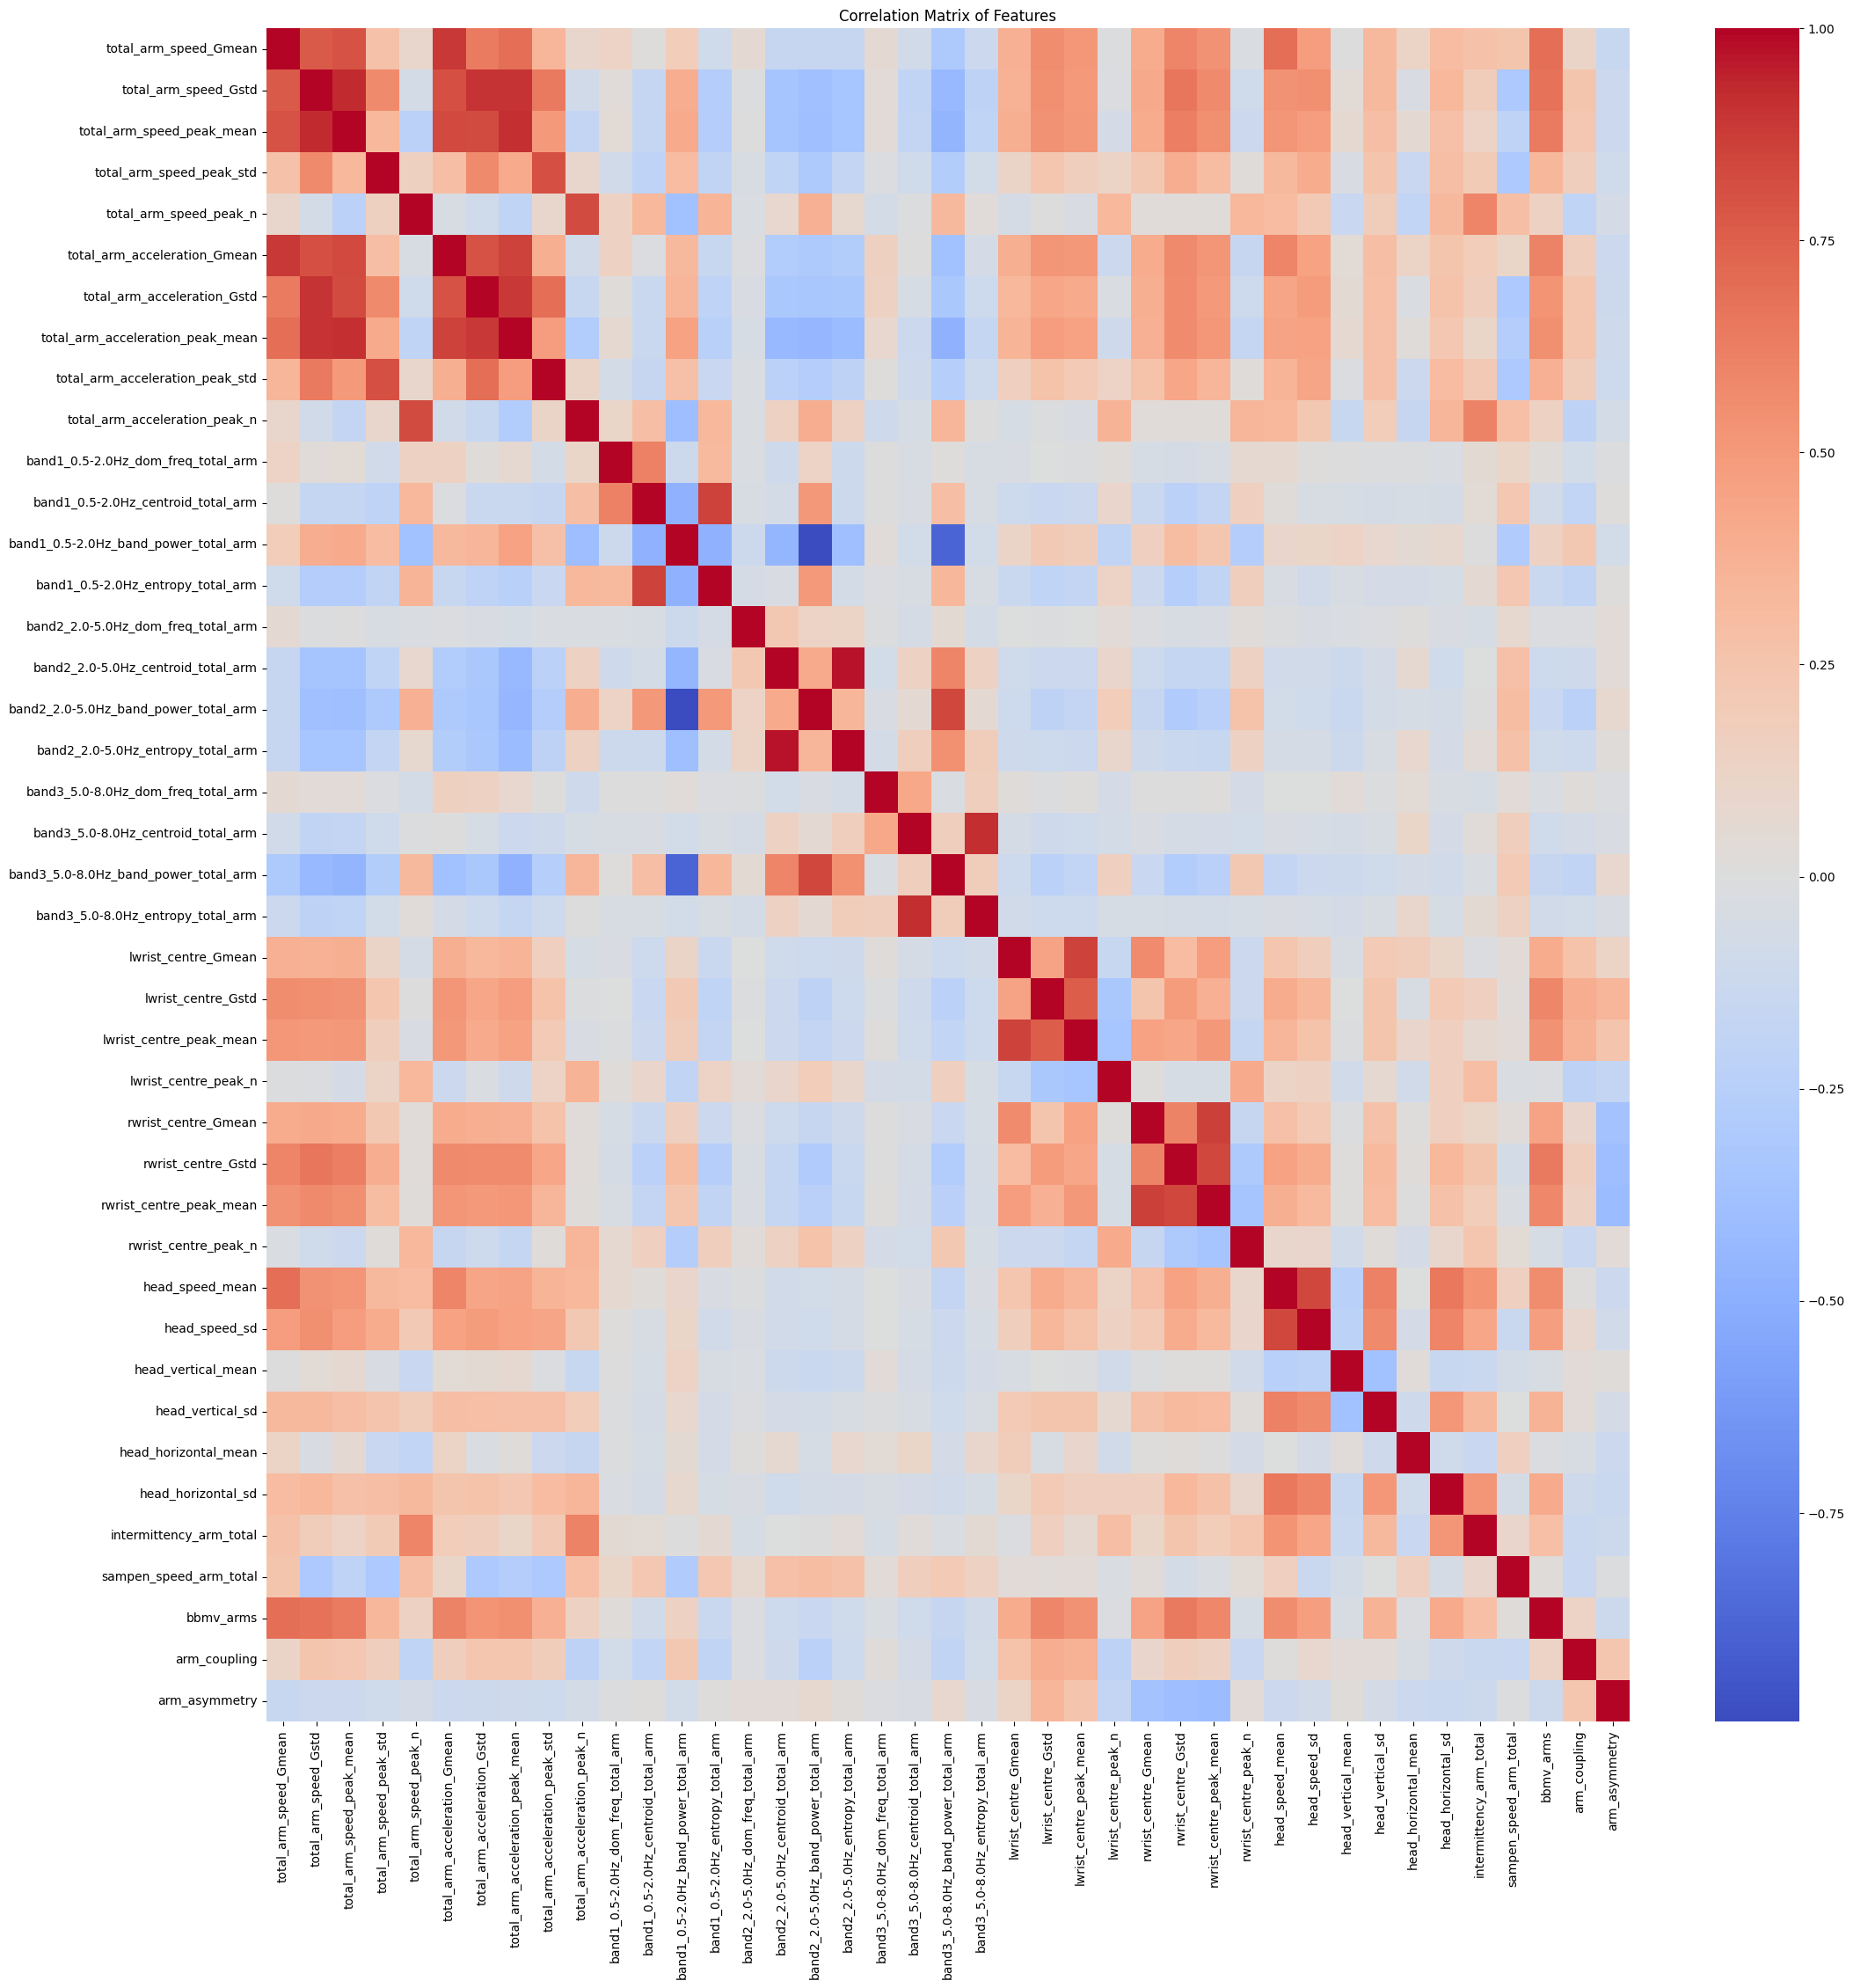

In [71]:
# create correlation matrix of all features to all and plot

# leave only numerical
numerical_cols = features_all_df.select_dtypes(include=[np.number]).columns
features_all_for_corr = features_all_df[numerical_cols]
correlation_matrix = features_all_for_corr.corr()


plt.figure(figsize=(25, 25))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Features')
plt.show()

In [73]:
# print all features that are highly correlated (above 0.7 or below -0.7) with each other
high_corr = correlation_matrix[(correlation_matrix > 0.7) | (correlation_matrix < -0.7)]
high_corr_pairs = high_corr.stack().reset_index()
high_corr_pairs.columns = ['Feature1', 'Feature2', 'Correlation']
# remove pairs where Feature1 == Feature2
high_corr_pairs = high_corr_pairs[high_corr_pairs['Feature1'] != high_corr_pairs['Feature2']]
# make a df of these pairs
high_corr_pairs = high_corr_pairs.dropna().sort_values(by='Correlation', ascending=False)
print('Highly correlated feature pairs (|correlation| > 0.7):')
high_corr_pairs

Highly correlated feature pairs (|correlation| > 0.7):


,Feature1,Feature2,Correlation
54,band2_2.0-5.0Hz_entropy_total_arm,band2_2.0-5.0Hz_centroid_total_arm,0.972185
50,band2_2.0-5.0Hz_centroid_total_arm,band2_2.0-5.0Hz_entropy_total_arm,0.972185
6,total_arm_speed_Gstd,total_arm_speed_peak_mean,0.926102
11,total_arm_speed_peak_mean,total_arm_speed_Gstd,0.926102
58,band3_5.0-8.0Hz_centroid_total_arm,band3_5.0-8.0Hz_entropy_total_arm,0.920025
62,band3_5.0-8.0Hz_entropy_total_arm,band3_5.0-8.0Hz_centroid_total_arm,0.920025
15,total_arm_speed_peak_mean,total_arm_acceleration_peak_mean,0.906990
32,total_arm_acceleration_peak_mean,total_arm_speed_peak_mean,0.906990
8,total_arm_speed_Gstd,total_arm_acceleration_Gstd,0.901351
26,total_arm_acceleration_Gstd,total_arm_speed_Gstd,0.901351


## UMAP

In [24]:
from math import floor

# random seed for reproducibility
np.random.seed(42)

features_df = features_all_df.copy()

# get rid of rows with nan in any col
features_df = features_df.dropna()

sampled_df_list = []

# Loop through each groupID
for groupID_val in features_df['groupID'].unique():
    sub_df = features_df[features_df['groupID'] == groupID_val]
    unique_groups = sub_df['group'].unique()
    n_groups = len(unique_groups)

    # Calculate how many samples per group to reach total of 150
    per_group_n = floor(250 / n_groups)

    for group_val in unique_groups:
        group_df = sub_df[sub_df['group'] == group_val]

        # Ensure we don’t oversample
        n_to_sample = min(per_group_n, len(group_df))
        sampled = group_df.sample(n=n_to_sample, random_state=42)
        sampled_df_list.append(sampled)

# Combine all sampled chunks
sampled_df = pd.concat(sampled_df_list).reset_index(drop=True)

    

In [25]:
import umap
from sklearn.preprocessing import StandardScaler

feat_df = sampled_df.copy()

# replace nan values with 0
#feat_df.fillna(0, inplace=True) 

reducer = umap.UMAP()

# get only numeric columns
features_df_num = feat_df._get_numeric_data()

# # drop NAs
# features_df_num = features_df_num.dropna()

# z-score all columns
features_df_scaled = StandardScaler().fit_transform(features_df_num)

# fit umap
embedding = reducer.fit_transform(features_df_scaled)
embedding.shape

(936, 2)

In [26]:
import plotly.express as px
import pandas as pd

# First, make a DataFrame that includes the embedding coordinates
plot_df = pd.DataFrame({
    'x': embedding[:, 0],
    'y': embedding[:, 1],
    'group': feat_df['group'],
    'groupID': feat_df['groupID'],
    'concept': feat_df['concept']
})

# Use Plotly Express for a scatter plot with hover
fig = px.scatter(
    plot_df,
    x='x',
    y='y',
    color='groupID',       # Color by groupID
    symbol='group',        # Optional: differentiate by shape if not too many categories
    hover_name='concept',  # Show the concept name when hovering
    hover_data=['group', 'groupID'],  # Show additional info on hover
    title='UMAP projection (interactive)',
    opacity=0.6
)

# Optional: fix aspect ratio like in matplotlib
fig.update_layout(
    autosize=False,
    width=900,
    height=800,
    title_font_size=24,
    yaxis=dict(scaleanchor="x", scaleratio=1)
)

fig.show()


# Fine motorics (hand)

In [4]:
handkinfiles = glob.glob(os.path.join(processedfolder, '*hands_kinematics.csv'))
handdistfiles = glob.glob(os.path.join(processedfolder, '*hands_distances.csv'))

print('Number of hand kinematics files:', len(handkinfiles))
print('Number of hand distances files:', len(handdistfiles))

handerrors = pd.read_csv(os.path.join(processedfolder, 'hand_processing_errors.csv'), sep=',', header=0)


Number of hand kinematics files: 12389
Number of hand distances files: 12389


## Errors

In [5]:
handerrors.head()

,error_type,file
0,missing values after interpolation,GP02_ANGELN.mp4_hands_hol.csv
1,missing values after interpolation,GP02_BODEN.mp4_hands_hol.csv
2,missing values after interpolation,GP02_FISCH.mp4_hands_hol.csv
3,missing values after interpolation,GP02_KITZELN.mp4_hands_hol.csv
4,missing values after interpolation,GP02_UMARMEN.mp4_hands_hol.csv


In [6]:
# get the unique pcnID (first element of the filename before the first )
handerrors['pcnID'] = handerrors['file'].apply(lambda x: x.split('_')[0])
# count how many times each pcnID appears in handerrors
handerrors_counts = handerrors['pcnID'].value_counts()
print('Number of unique pcnIDs in handerrors:', len(handerrors['pcnID'].unique()))
print('Number of times each pcnID appears in handerrors:')
print(handerrors_counts)

Number of unique pcnIDs in handerrors: 48
Number of times each pcnID appears in handerrors:
pcnID
IP10     209
LP33     154
LP29     135
LP18     129
LP17     125
LP01     121
LP30     116
LP36     113
LP43     104
LP38     103
LP42     100
IP08      97
GP08      95
LP07      94
LP34      93
GP05      93
GP15      92
LP40      61
IP14      59
LP14      58
LP22      57
LP08      56
LP04      53
LP06      53
LP15      47
IP16      43
LP41      39
GP16      37
LP13      33
LP25      30
GP17      24
GP11      19
GP14      15
IP11      14
GP04      13
GP10      13
LP28      11
IP06      10
IP18       9
LP19       8
GP02       6
ViCom      6
GP06       5
GP03       4
IP04       1
GP01       1
GP18       1
GtST       1
Name: count, dtype: int64


In [7]:
# replace hol.csv with distances.csv in file column
handerrors['file_kin'] = handerrors['file'].apply(lambda x: x.replace('hol.csv', 'kinematics.csv'))
handerrors['file_dist'] = handerrors['file'].apply(lambda x: x.replace('hol.csv', 'distances.csv'))

In [8]:
handkinfiles_clean = [f for f in handkinfiles if os.path.basename(f) not in handerrors['file_kin'].values]
handdistfiles_clean = [f for f in handdistfiles if os.path.basename(f) not in handerrors['file_dist'].values]

# How many percent was removed from each?
print('Percentage of files removed from handkinfiles:', (len(handkinfiles) - len(handkinfiles_clean)) / len(handkinfiles) * 100)
print('Percentage of files removed from handdistfiles:', (len(handdistfiles) - len(handdistfiles_clean)) / len(handdistfiles) * 100)

Percentage of files removed from handkinfiles: 22.205182016304786
Percentage of files removed from handdistfiles: 22.205182016304786


## Functions needed

In [9]:
sample_kin = pd.read_csv(handkinfiles_clean[0])
# replace kinematics with distances in the filename and find the corresponding distance file
sample_dist_file = handkinfiles_clean[0].replace('kinematics', 'distances')
sample_dist = pd.read_csv(sample_dist_file)


### Mean fingertip speed + std

This feature captures mean speed and std of all fingertips across time

In [94]:
def feature_fingertip_speed(df, side="RIGHT"):
    fingertip_cols = [
        f"{side}_INDEX_FINGER_TIP_speed",
        f"{side}_MIDDLE_FINGER_TIP_speed",
        f"{side}_RING_FINGER_TIP_speed",
        f"{side}_PINKY_FINGER_TIP_speed"
    ]
    
    available = [c for c in fingertip_cols if c in df.columns]
    
    if len(available) == 0:
        return np.nan
    
    speed_mean = df[available].mean().mean()
    speed_std = df[available].mean().std()
    
    return speed_mean, speed_std

# MediaPipe landmark IDs for fingertips (excluding thumb)
# 8=INDEX_TIP, 12=MIDDLE_TIP, 16=RING_TIP, 20=PINKY_TIP
# 0=WRIST (anchor)

FINGERTIP_TO_WRIST_IDS = {
    "INDEX":  8,
    "MIDDLE": 12,
    "RING":   16,
    "PINKY":  20,
}

def feature_fingertip_speed_distances(df, side="RIGHT"):
    """
    Compute mean and std of fingertip speed using the rate of change of 
    fingertip-to-wrist distances (from the distances dataframe).
    
    These are wrist-motion-independent by construction: they measure how 
    quickly the finger is opening/closing relative to the wrist, not 
    absolute spatial movement.
    
    Column naming convention: {side_prefix}{tip_id}_0_speed
      e.g. r8_0_speed = right index fingertip to wrist distance speed
    """
    side_prefix = "r" if side == "RIGHT" else "l"

    speed_cols = [
        f"{side_prefix}{tip_id}_0_speed"
        for tip_id in FINGERTIP_TO_WRIST_IDS.values()
    ]

    available = [c for c in speed_cols if c in df.columns]

    if len(available) == 0:
        return np.nan, np.nan

    # Mean over time for each finger, then summarise across fingers
    per_finger_means = df[available].mean()  # one value per finger
    speed_mean = per_finger_means.mean()
    speed_std  = per_finger_means.std()

    return speed_mean, speed_std


#--- usage ---
fingertip_speed_right, fingertip_speed_right_std = feature_fingertip_speed(
    sample_kin, side="RIGHT"
)
print("Mean fingertip speed (right):", fingertip_speed_right)
print("Std  fingertip speed (right):", fingertip_speed_right_std)

fingertip_dist_speed_right, fingertip_dist_speed_right_std = feature_fingertip_speed_distances(
    sample_dist, side="RIGHT"
)
print("Mean fingertip speed (right, distance-based):", fingertip_dist_speed_right)
print("Std fingertip speed (right, distance-based):", fingertip_dist_speed_right_std)



Mean fingertip speed (right): 31.744648011804607
Std  fingertip speed (right): 11.665954171086263
Mean fingertip speed (right, distance-based): 31.287146319285696
Std fingertip speed (right, distance-based): 11.752647341689784


### Mean finger tip smoothness

In [11]:
def feature_mean_fingertip_jerk(df, side="RIGHT"):
    jerk_cols = [
        f"{side}_INDEX_FINGER_TIP_jerk",
        f"{side}_MIDDLE_FINGER_TIP_jerk",
        f"{side}_RING_FINGER_TIP_jerk",
        f"{side}_PINKY_FINGER_TIP_jerk"
    ]
    
    available = [c for c in jerk_cols if c in df.columns]
    
    if len(available) == 0:
        return np.nan
    
    return df[available].mean().mean()

fingertip_jerk_right = feature_mean_fingertip_jerk(sample_kin, side="RIGHT")
print("Mean fingertip jerk (right):", fingertip_jerk_right)

Mean fingertip jerk (right): 0.08946114560921736


### Number of speed peaks per second (aka intermittency)

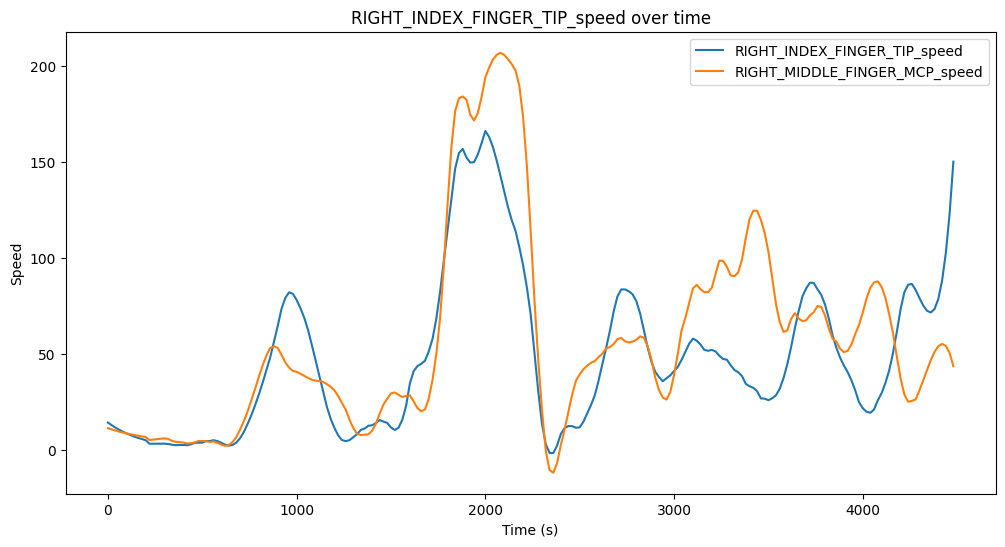

In [15]:
# plot RIGHT_WRIST_speed

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(sample_kin['time'], sample_kin['RIGHT_INDEX_FINGER_TIP_speed'], label='RIGHT_INDEX_FINGER_TIP_speed')
# plot also MCP
plt.plot(sample_kin['time'], sample_kin['RIGHT_MIDDLE_FINGER_MCP_speed'], label='RIGHT_MIDDLE_FINGER_MCP_speed')
plt.title('RIGHT_INDEX_FINGER_TIP_speed over time')
plt.xlabel('Time (s)')
plt.ylabel('Speed')
plt.legend()
plt.show()

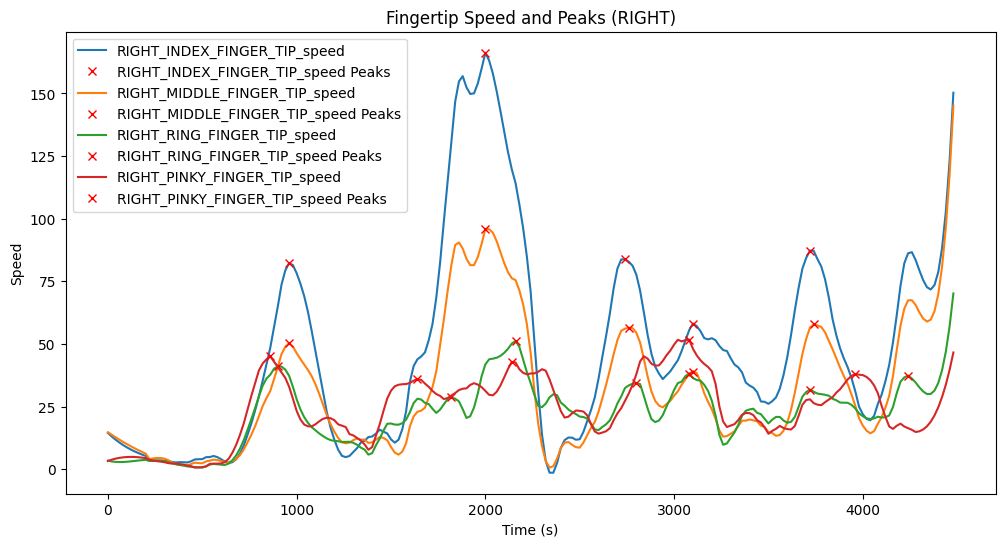

Fingertip peak rate (right): 4.888888888888889


In [16]:
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

def feature_fingertip_peak_rate(df, side="RIGHT", sr=30, plot=False):
    fingertip_cols = [
        f"{side}_INDEX_FINGER_TIP_speed",
        f"{side}_MIDDLE_FINGER_TIP_speed",
        f"{side}_RING_FINGER_TIP_speed",
        f"{side}_PINKY_FINGER_TIP_speed"
    ]
    
    available = [c for c in fingertip_cols if c in df.columns]
    if len(available) == 0:
        return np.nan

    total_peaks = 0
    total_time_sec = len(df) / sr

    for col in available:
        x = df[col].values
        peaks, _ = find_peaks(x, prominence=np.std(x) * 0.5)
        total_peaks += len(peaks)

    if plot:
        plt.figure(figsize=(12, 6))
        for col in available:
            plt.plot(df['time'], df[col], label=col)
            peaks, _ = find_peaks(df[col].values, prominence=np.std(df[col].values) * 0.5)
            plt.plot(df.loc[peaks, 'time'], df.loc[peaks, col], 'rx', label=f'{col} Peaks')
        plt.title(f'Fingertip Speed and Peaks ({side})')
        plt.xlabel('Time (s)')
        plt.ylabel('Speed')
        plt.legend()
        plt.show()

    return total_peaks / total_time_sec

# Get sr
if sample_kin['fileID'].iloc[0].startswith("LP") or sample_kin['fileID'].iloc[0].startswith("GtST"):
    sr = 30
else:
    sr = 50

fingertip_peak_rate_right = feature_fingertip_peak_rate(sample_kin, side="RIGHT", sr=sr, plot=True)
print("Fingertip peak rate (right):", fingertip_peak_rate_right)


Note: I think the fingers are still not independent from wrist movement

### Thumb-index distance (handshape aperture + stability)

In [17]:
from cv2 import mean


def feature_thumb_index_distance(df, side="RIGHT"):
    col = f"r4_8" if side == "RIGHT" else "l4_8"
    if col not in df.columns:
        return np.nan
    
    distance_mean = df[col].mean()
    distance_std = df[col].std()    
    return distance_mean, distance_std

thumb_index_distance_mean_right, thumb_index_distance_std_right = feature_thumb_index_distance(sample_dist, side="RIGHT")
print("Mean thumb-index distance (right):", thumb_index_distance_mean_right)
print("Std thumb-index distance (right):", thumb_index_distance_std_right)

Mean thumb-index distance (right): 6.763607070818137
Std thumb-index distance (right): 4.569902274189282


### Index-middle fingertip distance (finger spreading precision)

In [18]:
def feature_index_middle_distance(df, side="RIGHT"):
    col = f"r8_12" if side == "RIGHT" else "l8_12"
    if col not in df.columns:
        return np.nan
    
    distances_mean = df[col].mean()
    distances_std = df[col].std()

    return distances_mean, distances_std

index_middle_distance_mean_right, index_middle_distance_std_right = feature_index_middle_distance(sample_dist, side="RIGHT")
print("Mean index-middle distance (right):", index_middle_distance_mean_right)
print("Std index-middle distance (right):", index_middle_distance_std_right)


Mean index-middle distance (right): 5.610929779781658
Std index-middle distance (right): 3.755382294686553


### Tip-MCP mean distance

In [19]:
def feature_mcp_tip_distance(df, side="RIGHT"):
    tip_mcp_distances = [
        f"{side[0].lower()}4_2",  # thumb tip to thumb MCP
        f"{side[0].lower()}8_5",  # index tip to index MCP
        f"{side[0].lower()}12_9", # middle tip to middle MCP
        f"{side[0].lower()}16_13",  # ring tip to ring MCP
        f"{side[0].lower()}20_17"   # pinky tip to pinky MCP
    ]

    available = [c for c in tip_mcp_distances if c in df.columns]
    if len(available) == 0:
        return np.nan
    
    mean_distance = df[available].mean().mean()
    std_distance = df[available].mean().std()

    return mean_distance, std_distance

mcp_tip_distance_mean_right, mcp_tip_distance_std_right = feature_mcp_tip_distance(sample_dist, side="RIGHT")
print("Mean MCP-tip distance (right):", mcp_tip_distance_mean_right)
print("Std MCP-tip distance (right):", mcp_tip_distance_std_right)

Mean MCP-tip distance (right): 78.07076199521161
Std MCP-tip distance (right): 155.81065975593503


### Index-middle speed correlation (finger individuation)

In [20]:
def feature_finger_speed_correlation(df, side="RIGHT", f1="INDEX_FINGER_TIP", f2="MIDDLE_FINGER_TIP"):
    col1 = f"{side}_{f1}_speed"
    col2 = f"{side}_{f2}_speed"
    
    if col1 not in df.columns or col2 not in df.columns:
        return np.nan
    
    return df[col1].corr(df[col2])

finger_speed_corr_index_middle_right = feature_finger_speed_correlation(sample_kin, side="RIGHT")
print("Correlation of index and middle fingertip speed (right):", finger_speed_corr_index_middle_right)

finger_speed_corr_middle_ring_right = feature_finger_speed_correlation(sample_kin, side="RIGHT", f1="MIDDLE_FINGER_TIP", f2="RING_FINGER_TIP")
print("Correlation of middle and ring fingertip speed (right):", finger_speed_corr_middle_ring_right)

finger_speed_corr_ring_pinky_right = feature_finger_speed_correlation(sample_kin, side="RIGHT", f1="RING_FINGER_TIP", f2="PINKY_FINGER_TIP") # hardest to control, potentially very diagnostic
print("Correlation of ring and pinky fingertip speed (right):", finger_speed_corr_ring_pinky_right)



Correlation of index and middle fingertip speed (right): 0.9589972403642087
Correlation of middle and ring fingertip speed (right): 0.7828420745883562
Correlation of ring and pinky fingertip speed (right): 0.774689120584767


### Finger independence 

In [21]:
def feature_finger_independence(df, side="RIGHT"):
    pairs = [
        ("INDEX_FINGER_TIP", "MIDDLE_FINGER_TIP"),
        ("MIDDLE_FINGER_TIP", "RING_FINGER_TIP"),
        ("RING_FINGER_TIP", "PINKY_FINGER_TIP")
    ]
    corrs = []
    for f1, f2 in pairs:
        c1 = f"{side}_{f1}_speed"
        c2 = f"{side}_{f2}_speed"
        if c1 in df.columns and c2 in df.columns:
            corrs.append(df[c1].corr(df[c2]))
    if len(corrs) == 0:
        return np.nan
    return 1 - np.nanmean(corrs)

finger_independence_right = feature_finger_independence(sample_kin, side="RIGHT") # low = more coupled
print("Finger independence (right):", finger_independence_right)


Finger independence (right): 0.16115718815422264


### Handshape variability (sum of SDs of fingertip distances)

In [22]:
def feature_handshape_variability(df, side="RIGHT"):
    cols = [
        f"r4_8" if side == "RIGHT" else "l4_8",
        f"r8_12" if side == "RIGHT" else "l8_12",
        f"r12_16" if side == "RIGHT" else "l12_16",
        f"r16_20" if side == "RIGHT" else "l16_20"
    ]
    cols = [c for c in cols if c in df.columns]
    return df[cols].std().sum()

handshape_variability_right = feature_handshape_variability(sample_dist, side="RIGHT") # how much the entire handshape changes over time
print("Handshape variability (right):", handshape_variability_right)

Handshape variability (right): 16.848757553660345


### Finger to palm stability

In [23]:
def feature_fingertip_palm_stability(df, side="RIGHT"):
    cols = [
        f"{side}_INDEX_FINGER_TIP_speed",
        f"{side}_MIDDLE_FINGER_TIP_speed",
        f"{side}_RING_FINGER_TIP_speed",
        f"{side}_PINKY_FINGER_TIP_speed"
    ]
    cols = [c for c in cols if c in df.columns]
    return df[cols].std().mean()

fingertip_palm_stability_right = feature_fingertip_palm_stability(sample_kin, side="RIGHT") # how stable the fingertips are relative to the palm (low = more stable)
print("Fingertip-palm stability (right):", fingertip_palm_stability_right)

Fingertip-palm stability (right): 23.52242880034484


### Distant vs proximal motion

In [67]:
def feature_distal_proximal_ratio(df, side="RIGHT"):
    distal_cols = [
        f"{side}_INDEX_FINGER_TIP_speed",
        f"{side}_MIDDLE_FINGER_TIP_speed"
    ]
    prox_cols = [
        f"{side}_INDEX_FINGER_MCP_speed",
        f"{side}_MIDDLE_FINGER_MCP_speed"
    ]
    
    distal_cols = [c for c in distal_cols if c in df.columns]
    prox_cols = [c for c in prox_cols if c in df.columns]
    
    if len(distal_cols) == 0 or len(prox_cols) == 0:
        return np.nan
    
    return df[distal_cols].mean().mean() / (df[prox_cols].mean().mean() + 1e-6)

distal_proximal_ratio_right = feature_distal_proximal_ratio(sample_kin, side="RIGHT") # higher = more distal movement relative to proximal
print("Distal-proximal movement ratio (right):", distal_proximal_ratio_right)

Distal-proximal movement ratio (right): 0.6432707553971247


### Finger tip speed entropy (movement complexity)

In [25]:
from scipy.stats import entropy

def feature_speed_entropy(df, side="RIGHT"):
    col = f"{side}_INDEX_FINGER_TIP_speed"
    if col not in df.columns:
        return np.nan
    hist, _ = np.histogram(df[col].dropna(), bins=30, density=True)
    return entropy(hist + 1e-8)

speed_entropy_index_right = feature_speed_entropy(sample_kin, side="RIGHT") # higher = more variable speed
print("Speed entropy (index finger, right):", speed_entropy_index_right)

Speed entropy (index finger, right): 3.002003790491485


### Handshape and its variability (global hand aperture and stability)

In [26]:
def feature_handshape_size(df, side="RIGHT"):
    if side == "RIGHT":
        dist_cols = [c for c in df.columns if c.startswith("r") and "_" in c and not c.endswith("_x") and not c.endswith("_y") and not c.endswith("_z")]
    else:
        dist_cols = [c for c in df.columns if c.startswith("l") and "_" in c and not c.endswith("_x") and not c.endswith("_y") and not c.endswith("_z")]

    dist_cols = [c for c in dist_cols if df[c].dtype != object]

    mean = df[dist_cols].mean(axis=1).mean()
    std = df[dist_cols].std(axis=1).mean()

    return mean, std

handshape_size_mean_right, handshape_size_std_right = feature_handshape_size(sample_dist, side="RIGHT") # how large the handshape is (mean distance between fingers)
print("Handshape size mean (right):", handshape_size_mean_right) # higher = more open
print("Handshape size std (right):", handshape_size_std_right) # higher = unstable handshape


Handshape size mean (right): 18.417667830461973
Handshape size std (right): 55.2505512526247


### One function rules them all

In [68]:
def extract_all_finger_features(df_kin, df_dist, side="RIGHT", sr=30):
    features = {}
    
    # Fingertip speed
    fingertip_speed_mean, fingertip_speed_std = feature_fingertip_speed(df_kin, side)
    features[f"{side}_fingertip_speed_mean"] = fingertip_speed_mean
    features[f"{side}_fingertip_speed_std"] = fingertip_speed_std
    
    # Fingertip jerk
    fingertip_jerk_mean = feature_mean_fingertip_jerk(df_kin, side)
    features[f"{side}_fingertip_jerk_mean"] = fingertip_jerk_mean
    
    # Fingertip peak rate
    sr = 30 if df_kin['fileID'].iloc[0].startswith("LP") or df_kin['fileID'].iloc[0].startswith("GtST") else 50
    fingertip_peak_rate = feature_fingertip_peak_rate(df_kin, side, sr)
    features[f"{side}_fingertip_peak_rate"] = fingertip_peak_rate
    
    # Thumb-index distance
    thumb_index_distance_mean, thumb_index_distance_std = feature_thumb_index_distance(df_dist, side)
    features[f"{side}_thumb_index_distance_mean"] = thumb_index_distance_mean
    features[f"{side}_thumb_index_distance_std"] = thumb_index_distance_std
    
    # Index-middle distance
    index_middle_distance_mean, index_middle_distance_std = feature_index_middle_distance(df_dist, side)
    features[f"{side}_index_middle_distance_mean"] = index_middle_distance_mean
    features[f"{side}_index_middle_distance_std"] = index_middle_distance_std
    
    # MCP-tip distance
    mcp_tip_distance_mean, mcp_tip_distance_std = feature_mcp_tip_distance(df_dist, side)
    features[f"{side}_mcp_tip_distance_mean"] = mcp_tip_distance_mean
    features[f"{side}_mcp_tip_distance_std"] = mcp_tip_distance_std
    
    # Finger speed correlation
    finger_speed_corr_index_middle = feature_finger_speed_correlation(df_kin, side)
    features[f"{side}_finger_speed_corr_index_middle"] = finger_speed_corr_index_middle
    
    finger_speed_corr_middle_ring = feature_finger_speed_correlation(df_kin, side, f1="MIDDLE_FINGER_TIP", f2="RING_FINGER_TIP")
    features[f"{side}_finger_speed_corr_middle_ring"] = finger_speed_corr_middle_ring
    
    finger_speed_corr_ring_pinky = feature_finger_speed_correlation(df_kin, side, f1="RING_FINGER_TIP", f2="PINKY_FINGER_TIP")
    features[f"{side}_finger_speed_corr_ring_pinky"] = finger_speed_corr_ring_pinky

    # Finger independence
    finger_independence = feature_finger_independence(df_kin, side)
    features[f"{side}_finger_independence"] = finger_independence

    # Distal-proximal ratio
    distal_proximal_ratio = feature_distal_proximal_ratio(df_kin, side)
    features[f"{side}_distal_proximal_ratio"] = distal_proximal_ratio

    # Handshape variability
    handshape_size_mean, handshape_size_std = feature_handshape_size(df_dist, side)
    features[f"{side}_handshape_size_mean"] = handshape_size_mean
    features[f"{side}_handshape_size_std"] = handshape_size_std

    # Speed entropy
    speed_entropy = feature_speed_entropy(df_kin, side)
    features[f"{side}_speed_entropy"] = speed_entropy

    return features

# Example usage:
right_hand_features = extract_all_finger_features(sample_kin, sample_dist, side="RIGHT")
print("Extracted right hand features:")
for key, value in right_hand_features.items():
    print(f"{key}: {value}")

Extracted right hand features:
RIGHT_fingertip_speed_mean: 31.744648011804607
RIGHT_fingertip_speed_std: 11.665954171086263
RIGHT_fingertip_jerk_mean: 0.08946114560921736
RIGHT_fingertip_peak_rate: 4.888888888888889
RIGHT_thumb_index_distance_mean: 6.763607070818137
RIGHT_thumb_index_distance_std: 4.569902274189282
RIGHT_index_middle_distance_mean: 5.610929779781658
RIGHT_index_middle_distance_std: 3.755382294686553
RIGHT_mcp_tip_distance_mean: 78.07076199521161
RIGHT_mcp_tip_distance_std: 155.81065975593503
RIGHT_finger_speed_corr_index_middle: 0.9589972403642087
RIGHT_finger_speed_corr_middle_ring: 0.7828420745883562
RIGHT_finger_speed_corr_ring_pinky: 0.774689120584767
RIGHT_finger_independence: 0.16115718815422264
RIGHT_distal_proximal_ratio: 0.6432707553971247
RIGHT_handshape_size_mean: 18.417667830461973
RIGHT_handshape_size_std: 55.2505512526247
RIGHT_speed_entropy: 3.002003790491485


## Full loop for hand/finger kinematics

In [69]:
# prepare empty df
finger_features_df = pd.DataFrame()

# Loop through all files and extract features
for kin_file in handkinfiles_clean:

    print(f"Processing {kin_file}...")
    
    dist_file = kin_file.replace('kinematics', 'distances')
    
    if not os.path.exists(dist_file):
        print(f"Distance file not found for {kin_file}, skipping.")
        continue
    
    df_kin = pd.read_csv(kin_file)
    df_dist = pd.read_csv(dist_file)
    
    features_right = extract_all_finger_features(df_kin, df_dist, side="RIGHT")
    features_left = extract_all_finger_features(df_kin, df_dist, side="LEFT")
    
    all_features = {**features_right, **features_left}
    all_features['fileID'] = df_kin['fileID'].iloc[0]

    # META
    if 'GtST' in all_features['fileID'] or 'GP' in all_features['fileID']:
        all_features['group'] = all_features['fileID'].split('_')[0]
    elif 'LP' in all_features['fileID'] or 'IP' in all_features['fileID']:
        all_features['group'] = all_features['fileID'].split('_')[0] + '_' + all_features['fileID'].split('_')[1]
    elif 'ViCom' in all_features['fileID']:
        all_features['group'] = 'ViCom'
    else:
        print('ERROR: fileID not in GtST, GP, LP, IP')
        continue

    # CONCEPT
    if 'GtST' in all_features['fileID']:
        all_features['concept'] = all_features['fileID'].split('_')[2].split('.')[0]
    elif 'GP' in all_features['fileID']:
        all_features['concept'] = all_features['fileID'].split('_')[1].split('.')[0]
    elif 'LP' in all_features['fileID'] or 'IP' in all_features['fileID']:
        all_features['concept'] = all_features['fileID'].split('_')[2].split('.')[0]
    elif 'ViCom' in all_features['fileID']:
        all_features['concept'] = all_features['fileID'].split('_')[3].split('.')[0]

    # corrections
    if all_features['concept'] == 'TO-PICK':
        all_features['concept'] = 'TO-PLUCK'
    elif all_features['concept'] == 'TO-MOVE-HOUSES':
        all_features['concept'] = 'TO-MOVE'
    elif all_features['concept'] == 'VIDEO-GAME':
        all_features['concept'] = 'VIDEOGAME'
    
    finger_features_df = pd.concat([finger_features_df, pd.DataFrame([all_features])], ignore_index=True)

    #break

Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_(AUF)PUMPEN.mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ABEND.mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ABHOLEN.mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ADLER.mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ABLEHNEN.mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_AFFE.mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ABTROCKNEN .mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_AKKORDEON.mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ALT.mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_ANFANG.mp4_hands_kinematics.csv...
Processing e:\GtST_FLESH_KinTrajectory\TS_processed\GP02_APFEL.mp4_hand

In [70]:
# save the features
finger_features_df.to_csv(os.path.join(datasetsfolder, 'hand_finger_features.csv'), index=False)

### Aftermath

In [71]:
#dfs = [features_all_df, features_kin_df, features_dist_df, features_hand_df]
dfs = [finger_features_df]


def classify_group(x):
    if 'IP' in x and '_02' in x:
        return 'Learners_2'
    elif 'IP' in x and '_01' in x:
        return 'Learners_1'
    elif 'LP' in x and '_02' in x:
        return 'Learners_2'
    elif 'LP' in x and '_01' in x:
        return 'Learners_1'
    elif 'GtST' in x or 'ViCom' in x:
        return 'DGS'
    elif 'GP' in x:
        return 'Gesture'
    elif 'test' in x:
        return 'test'
    else:
        return x

# for each df, replace the group names
for df in dfs:
    df['group'] = df['group'].apply(lambda x: 'ViCom' if 'ViCom_' in x else x)
    df['group'] = df['group'].apply(lambda x: 'ViCom' if 'GtST_' in x else x)
    df['groupID'] = df['group'].apply(classify_group)
    # filter out rows where group=test or groupID=test
    df = df[df['group'] != 'test']
    df = df[df['groupID'] != 'test']

# save them datasetsfolder
finger_features_df.to_csv(os.path.join(datasetsfolder, 'features_fine_df_final.csv'), index=False)


In [72]:
# within each col groupID, how many different values of col group there is?
group_counts = finger_features_df.groupby('groupID')['group'].nunique().reset_index()
group_counts.columns = ['groupID', 'unique_groups_count']
group_counts

,groupID,unique_groups_count
0,DGS,2
1,Gesture,14
2,Learners_1,31
3,Learners_2,20


In [97]:
# how many rows there is per each groupID?
group_row_counts = finger_features_df['group'].value_counts().reset_index()
group_row_counts.columns = ['group', 'row_count']
group_row_counts

,group,row_count
0,GP18,362
1,GP01,362
2,GP03,359
3,GP06,358
4,GP02,357
...,...,...
62,LP29_01,58
63,IP10_02,51
64,LP33_02,49
65,LP43_02,33


In [73]:
# show me percentage of nans per column
nan_percentage = finger_features_df.isna().mean() * 100
print('Percentage of NaNs per column:')
nan_percentage[nan_percentage > 0].sort_values(ascending=False)



Percentage of NaNs per column:


Series([], dtype: float64)

### Correlation matrix

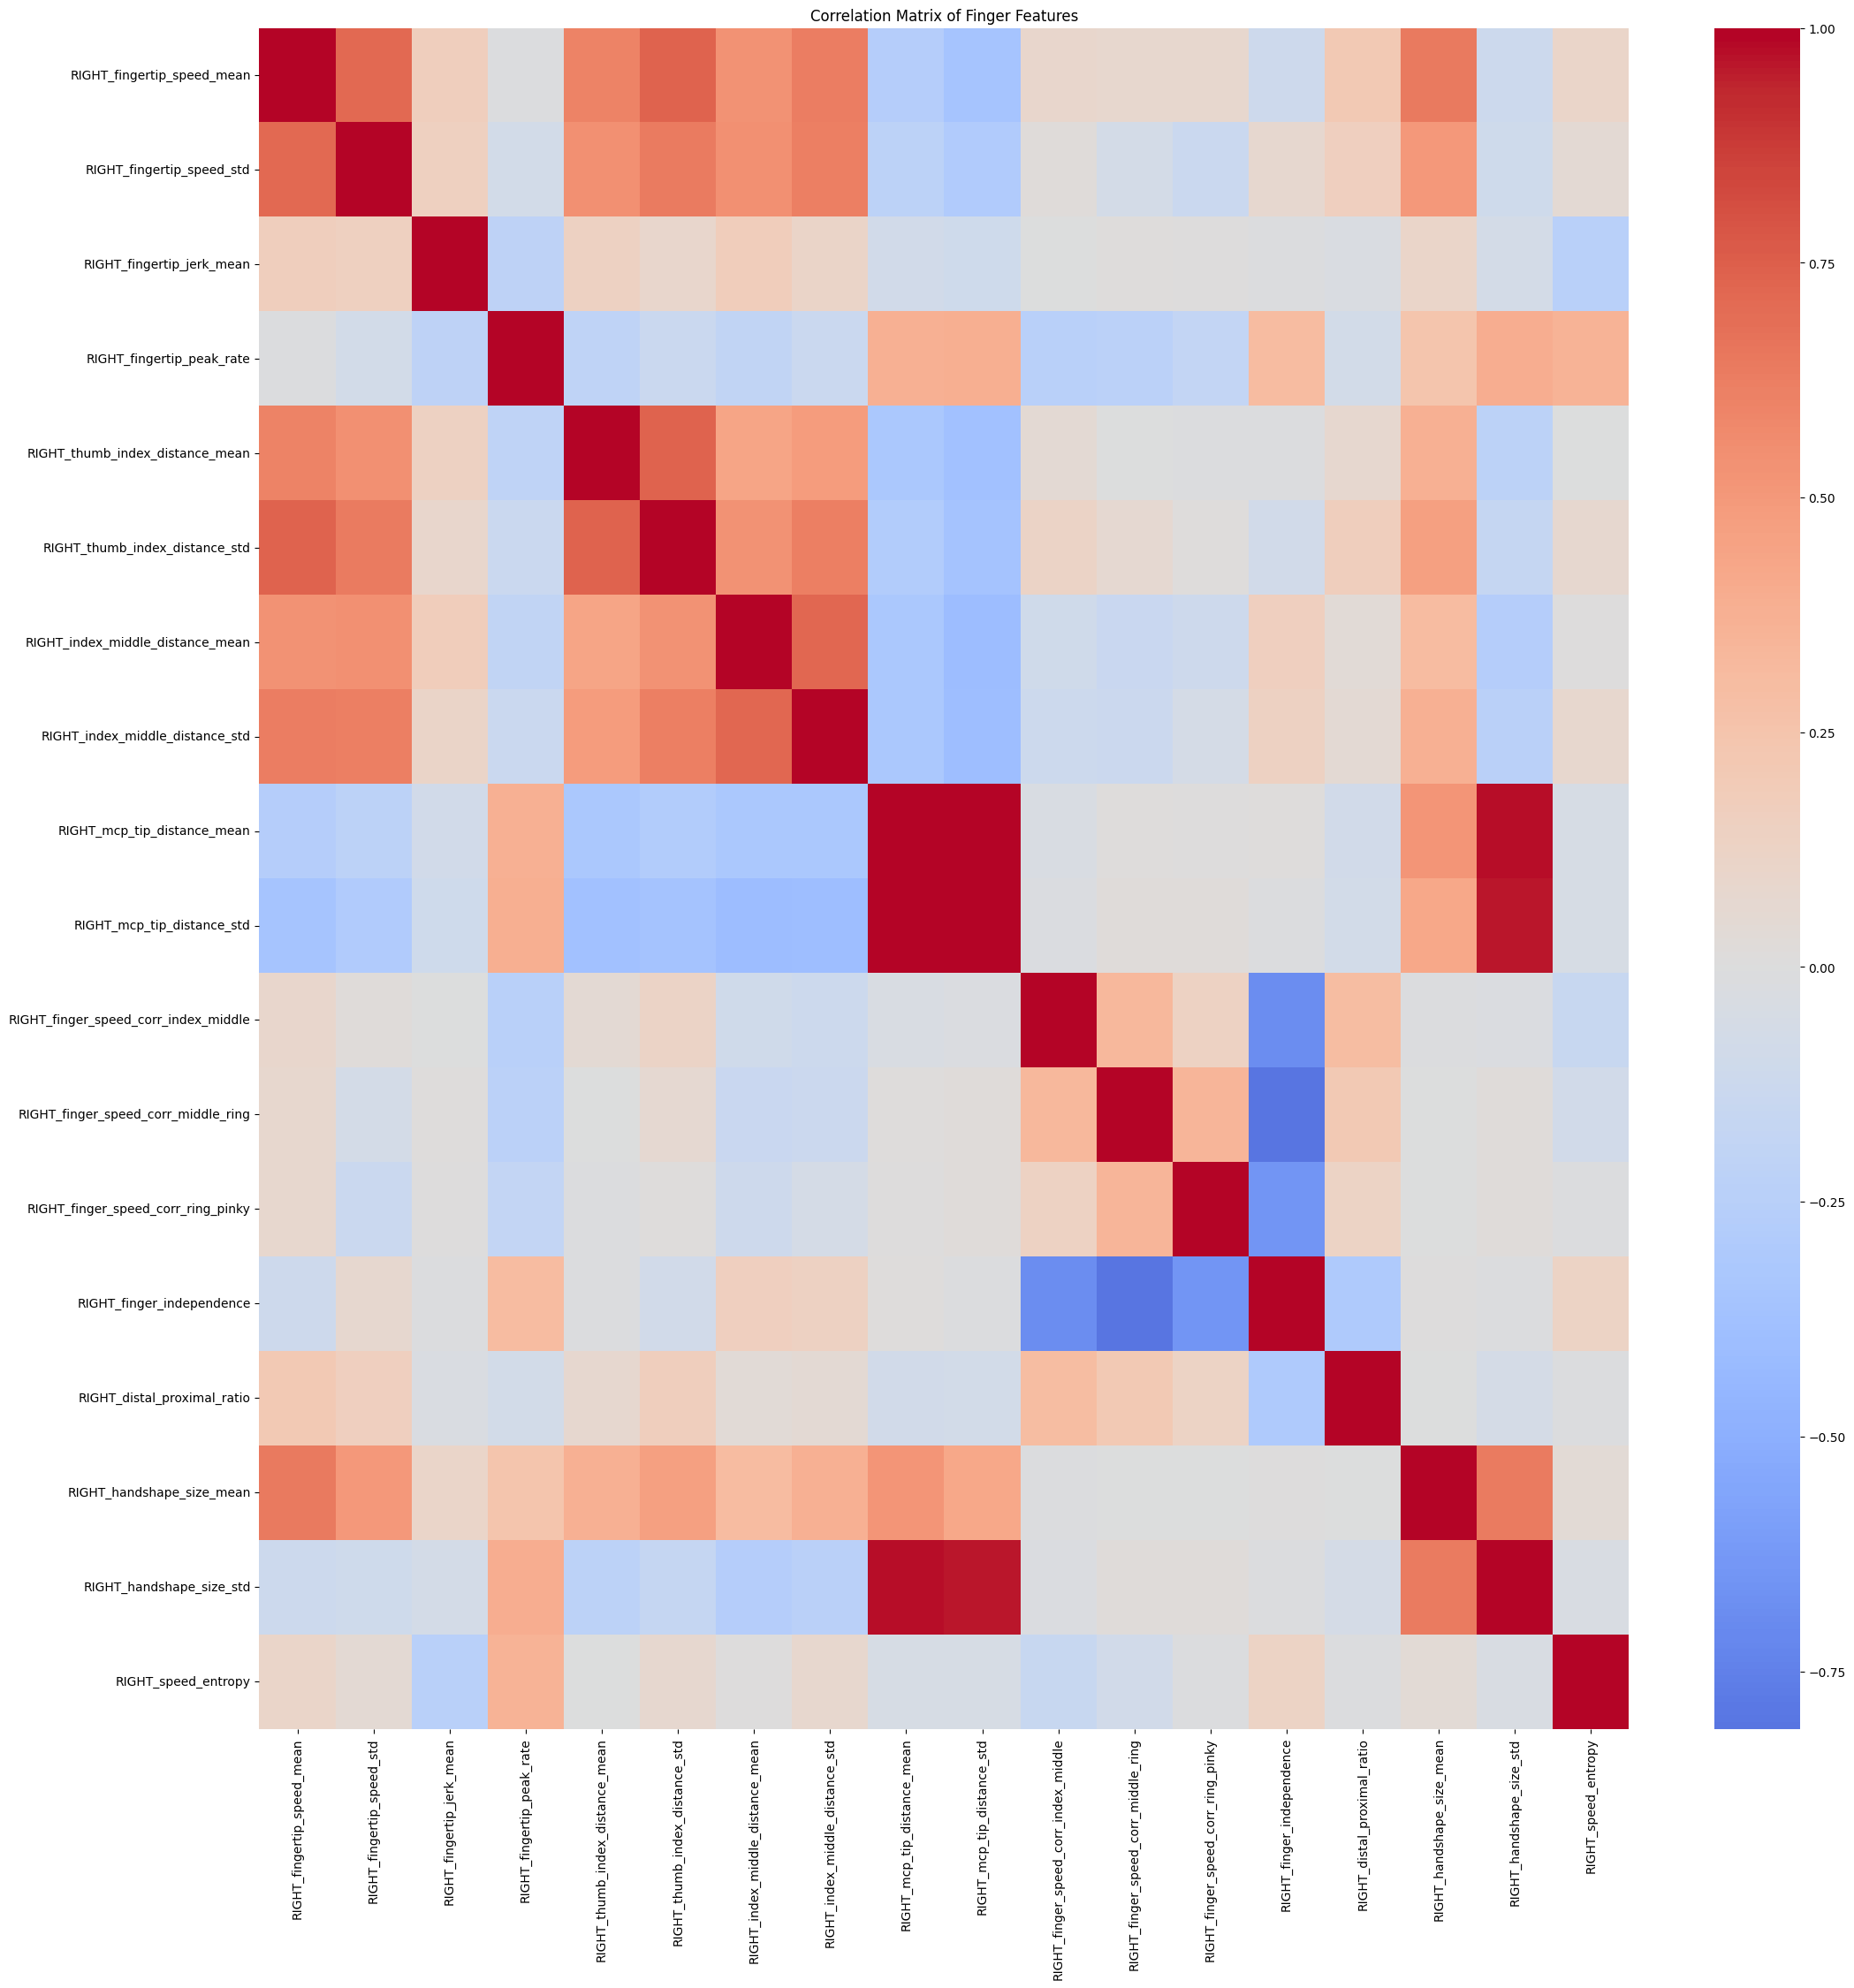

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

# get only numerical columns
numerical_cols = finger_features_df.select_dtypes(include=[np.number]).columns

# keep only columns with RIGHT_
numerical_cols = [col for col in numerical_cols if 'RIGHT_' in col]
features_df_num = finger_features_df[numerical_cols]

correlation_matrix = features_df_num.corr()
plt.figure(figsize=(25, 25))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Finger Features')
plt.show()

In [77]:
# print all features that are highly correlated (above 0.7 or below -0.7) with each other
high_corr = correlation_matrix[(correlation_matrix > 0.7) | (correlation_matrix < -0.7)]
high_corr_pairs = high_corr.stack().reset_index()
high_corr_pairs.columns = ['Feature1', 'Feature2', 'Correlation']
# remove pairs where Feature1 == Feature2
high_corr_pairs = high_corr_pairs[high_corr_pairs['Feature1'] != high_corr_pairs['Feature2']]
# make a df of these pairs
high_corr_pairs = high_corr_pairs.dropna().sort_values(by='Correlation', ascending=False)
print('Highly correlated feature pairs (|correlation| > 0.7):')
high_corr_pairs

Highly correlated feature pairs (|correlation| > 0.7):


,Feature1,Feature2,Correlation
17,RIGHT_mcp_tip_distance_mean,RIGHT_mcp_tip_distance_std,0.989157
19,RIGHT_mcp_tip_distance_std,RIGHT_mcp_tip_distance_mean,0.989157
18,RIGHT_mcp_tip_distance_mean,RIGHT_handshape_size_std,0.976865
30,RIGHT_handshape_size_std,RIGHT_mcp_tip_distance_mean,0.976865
21,RIGHT_mcp_tip_distance_std,RIGHT_handshape_size_std,0.962062
31,RIGHT_handshape_size_std,RIGHT_mcp_tip_distance_std,0.962062
8,RIGHT_thumb_index_distance_mean,RIGHT_thumb_index_distance_std,0.734416
10,RIGHT_thumb_index_distance_std,RIGHT_thumb_index_distance_mean,0.734416
2,RIGHT_fingertip_speed_mean,RIGHT_thumb_index_distance_std,0.731737
9,RIGHT_thumb_index_distance_std,RIGHT_fingertip_speed_mean,0.731737


### UMAP

In [78]:
from math import floor

# random seed for reproducibility
np.random.seed(42)

features_df = finger_features_df.copy()

# get rid of rows with nan in any col
features_df = features_df.dropna()

sampled_df_list = []

# Loop through each groupID
for groupID_val in features_df['groupID'].unique():
    sub_df = features_df[features_df['groupID'] == groupID_val]
    unique_groups = sub_df['group'].unique()
    n_groups = len(unique_groups)

    # Calculate how many samples per group to reach total of 150
    per_group_n = floor(250 / n_groups)

    for group_val in unique_groups:
        group_df = sub_df[sub_df['group'] == group_val]

        # Ensure we don’t oversample
        n_to_sample = min(per_group_n, len(group_df))
        sampled = group_df.sample(n=n_to_sample, random_state=42)
        sampled_df_list.append(sampled)

# Combine all sampled chunks
sampled_df = pd.concat(sampled_df_list).reset_index(drop=True)

    

In [79]:
import umap
from sklearn.preprocessing import StandardScaler

feat_df = sampled_df.copy()

# replace nan values with 0
#feat_df.fillna(0, inplace=True) 

reducer = umap.UMAP()

# get only numeric columns
features_df_num = feat_df._get_numeric_data()

# # drop NAs
# features_df_num = features_df_num.dropna()

# z-score all columns
features_df_scaled = StandardScaler().fit_transform(features_df_num)

# fit umap
embedding = reducer.fit_transform(features_df_scaled)
embedding.shape

(976, 2)

In [80]:
import plotly.express as px
import pandas as pd

# First, make a DataFrame that includes the embedding coordinates
plot_df = pd.DataFrame({
    'x': embedding[:, 0],
    'y': embedding[:, 1],
    'group': feat_df['group'],
    'groupID': feat_df['groupID'],
    'concept': feat_df['concept']
})

# Use Plotly Express for a scatter plot with hover
fig = px.scatter(
    plot_df,
    x='x',
    y='y',
    color='groupID',       # Color by groupID
    symbol='group',        # Optional: differentiate by shape if not too many categories
    hover_name='concept',  # Show the concept name when hovering
    hover_data=['group', 'groupID'],  # Show additional info on hover
    title='UMAP projection (interactive)',
    opacity=0.6
)

# Optional: fix aspect ratio like in matplotlib
fig.update_layout(
    autosize=False,
    width=900,
    height=800,
    title_font_size=24,
    yaxis=dict(scaleanchor="x", scaleratio=1)
)

fig.show()


# Put both dataframes together

In [101]:
df_gross = pd.read_csv(os.path.join(datasetsfolder, 'features_gross_df_final_reduced.csv'))
df_fine = pd.read_csv(os.path.join(datasetsfolder, 'features_fine_df_final.csv'))

# in df_gross, get rid of the last two elements (sep by _) in fileID
df_gross['fileID'] = df_gross['fileID'].apply(lambda x: '_'.join(x.split('_')[:-2]))

# in df_fine, get rid of the last two elements (sep by .) in fileID
df_fine['fileID'] = df_fine['fileID'].apply(lambda x: x.split('.')[0])
# get rid of all LEFT_
df_fine = df_fine[[col for col in df_fine.columns if not col.startswith('LEFT_')]]

# now merge on fileID
merged_df = pd.merge(df_gross, df_fine, on=['fileID', 'concept', 'group', 'groupID'], how='left')

In [102]:
merged_df.head()

,fileID,concept,group,total_arm_speed_Gmean,total_arm_speed_Gstd,total_arm_speed_peak_mean,total_arm_speed_peak_std,total_arm_speed_peak_n,total_arm_acceleration_Gmean,total_arm_acceleration_Gstd,...,RIGHT_mcp_tip_distance_mean,RIGHT_mcp_tip_distance_std,RIGHT_finger_speed_corr_index_middle,RIGHT_finger_speed_corr_middle_ring,RIGHT_finger_speed_corr_ring_pinky,RIGHT_finger_independence,RIGHT_distal_proximal_ratio,RIGHT_handshape_size_mean,RIGHT_handshape_size_std,RIGHT_speed_entropy
0,LP28_01_BASKETBALL,BASKETBALL,LP28_01,57.034382,37.296268,129.833209,36.817494,2,5.295914,4.069127,...,8.253318,2.591501,0.976573,0.922353,0.956180,0.048298,1.285168,7.039336,10.937566,2.920993
1,LP28_01_BEINE,BEINE,LP28_01,28.505895,30.110497,89.123921,53.049432,2,3.508353,3.200335,...,29.633083,38.577484,0.652833,0.912674,0.892862,0.180544,0.600849,7.594148,16.915966,3.049467
2,LP28_01_BEOBACHTEN,BEOBACHTEN,LP28_01,50.109067,48.503724,155.899277,23.157660,2,5.747850,4.731763,...,24.121358,31.706464,0.904093,0.914548,0.954634,0.075575,1.309415,8.074251,15.294719,2.815971
3,LP28_01_BEZAHLEN,BEZAHLEN,LP28_01,51.492183,51.291439,127.326846,69.332169,3,7.622287,5.600085,...,29.672452,38.658052,0.696058,0.472548,0.884084,0.315770,0.649863,6.870828,15.299633,3.073458
4,LP28_01_BIER,BIER,LP28_01,54.221475,58.220788,162.213995,55.325826,3,7.275411,6.538960,...,23.128778,22.766031,0.968341,0.917084,0.972282,0.047431,0.879580,8.779597,16.895711,2.934233


In [104]:
# how many rows have RIGHT_distal_proximal_ratio empty
num_missing = merged_df['RIGHT_distal_proximal_ratio'].isna().sum()
print(f"Number of rows with missing RIGHT_distal_proximal_ratio: {num_missing}")

# get rid of those rows
merged_df_clean = merged_df.dropna(subset=['RIGHT_distal_proximal_ratio'])
print(f"Number of rows after dropping missing RIGHT_distal_proximal_ratio: {len(merged_df_clean)}")

# save the merged df
merged_df_clean.to_csv(os.path.join(datasetsfolder, 'features_merged_clean_df.csv'), index=False)



Number of rows with missing RIGHT_distal_proximal_ratio: 1810
Number of rows after dropping missing RIGHT_distal_proximal_ratio: 8663


In [105]:
merged_df_clean

,fileID,concept,group,total_arm_speed_Gmean,total_arm_speed_Gstd,total_arm_speed_peak_mean,total_arm_speed_peak_std,total_arm_speed_peak_n,total_arm_acceleration_Gmean,total_arm_acceleration_Gstd,...,RIGHT_mcp_tip_distance_mean,RIGHT_mcp_tip_distance_std,RIGHT_finger_speed_corr_index_middle,RIGHT_finger_speed_corr_middle_ring,RIGHT_finger_speed_corr_ring_pinky,RIGHT_finger_independence,RIGHT_distal_proximal_ratio,RIGHT_handshape_size_mean,RIGHT_handshape_size_std,RIGHT_speed_entropy
0,LP28_01_BASKETBALL,BASKETBALL,LP28_01,57.034382,37.296268,129.833209,36.817494,2,5.295914,4.069127,...,8.253318,2.591501,0.976573,0.922353,0.956180,0.048298,1.285168,7.039336,10.937566,2.920993
1,LP28_01_BEINE,BEINE,LP28_01,28.505895,30.110497,89.123921,53.049432,2,3.508353,3.200335,...,29.633083,38.577484,0.652833,0.912674,0.892862,0.180544,0.600849,7.594148,16.915966,3.049467
2,LP28_01_BEOBACHTEN,BEOBACHTEN,LP28_01,50.109067,48.503724,155.899277,23.157660,2,5.747850,4.731763,...,24.121358,31.706464,0.904093,0.914548,0.954634,0.075575,1.309415,8.074251,15.294719,2.815971
3,LP28_01_BEZAHLEN,BEZAHLEN,LP28_01,51.492183,51.291439,127.326846,69.332169,3,7.622287,5.600085,...,29.672452,38.658052,0.696058,0.472548,0.884084,0.315770,0.649863,6.870828,15.299633,3.073458
4,LP28_01_BIER,BIER,LP28_01,54.221475,58.220788,162.213995,55.325826,3,7.275411,6.538960,...,23.128778,22.766031,0.968341,0.917084,0.972282,0.047431,0.879580,8.779597,16.895711,2.934233
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10468,GP16_SCHNEIDEN_(Messer),SCHNEIDEN,GP16,104.505993,40.168823,155.708391,12.868426,6,8.807392,4.587389,...,92.521474,191.790834,0.727964,0.788496,0.490986,0.330852,0.835735,14.770831,65.130103,2.521838
10469,GP16_SCHNEIDEN_(Schere),SCHNEIDEN,GP16,62.681245,54.054187,105.513076,71.523735,5,5.504192,4.777856,...,70.560422,136.240527,0.717180,0.553352,0.490667,0.412933,0.693680,11.241656,47.058484,2.941628
10470,GP17_MORGEN_(nicht_heute),MORGEN,GP17,67.058994,56.318131,204.513893,7.493390,2,6.828230,5.595297,...,104.691417,225.395816,0.901303,0.636221,0.811218,0.217086,0.925979,15.351785,73.875127,3.073469
10471,GP17_MORGEN_(Tageszeit),MORGEN,GP17,62.273488,51.032825,143.153557,39.729694,4,6.222866,4.834234,...,108.013010,227.596184,0.776812,0.889005,0.923099,0.137028,0.537238,15.219592,74.831347,3.104686


In [108]:
# load in merged df
merged_df_clean = pd.read_csv(os.path.join(datasetsfolder, 'features_merged_clean_df.csv'))

In [109]:
# create UMAP of merged_df_clean

import umap

# get only numeric columns
features_df_num = merged_df_clean.select_dtypes(include=[np.number])
# get rid of rows with nan
features_df_num = features_df_num.dropna()
# z-score all columns
features_df_scaled = StandardScaler().fit_transform(features_df_num)
reducer = umap.UMAP()
embedding = reducer.fit_transform(features_df_scaled)
# make a DataFrame that includes the embedding coordinates
plot_df = pd.DataFrame({
    "UMAP1": embedding[:, 0],
    "UMAP2": embedding[:, 1]
})

# add groupID and concept to plot_df
plot_df["groupID"] = merged_df_clean["groupID"]
plot_df["concept"] = merged_df_clean["concept"]
# plot with plotly
import plotly.express as px

fig = px.scatter(
    plot_df,
    x="UMAP1",
    y="UMAP2",
    color="groupID",
    hover_name="concept",
    title="UMAP of Merged Features",
    opacity=0.7
)

fig.update_layout(
    autosize=False,
    width=900,
    height=800,
    title_font_size=24,
    yaxis=dict(scaleanchor="x", scaleratio=1)
)

fig.show()